# Phase 3A | First hybrid neural digital twin 🧠
**Data-anchored spontaneous neural dynamics + explicitly hypothetical optogenetic drive**

### What we are building

1. Fit a **nonnegative, leaky neural-population rate model** on real mouse hippocampal recordings from **DANDI 000568**.
2. Fit a **GRU** to predict the next 100-ms population firing rate, and a **hybrid GRU** to learn residual corrections to the leaky model.
3. Test *measured* neural-dynamics predictions on a **completely held-out recording session** (two directions; both sessions are from the **same mouse**).
4. Add an **assumed, unitless light-drive mechanism** to simulate possible excitatory and inhibitory responses. The light-response strength is **NOT inferred or validated** from this dataset.
5. Export actual-model metrics and *separately labeled* hypothetical intervention simulations.

**Scope:** This is a computational proof-of-concept, **not** a human epilepsy treatment model, a clinically validated digital twin, demonstrated optical causation, or cross-animal personalization. Do **not** report the simulated light-response curves as real biological outcomes.

**Data:** Two small `+ogen`, `no-raw-data` NWB files (~73 MB combined), version-pinned DANDI 000568: https://dandiarchive.org/dandiset/000568 . No Kaggle dataset input required. **Internet ON; CPU sufficient.**

## 1 · Setup

- `QUICK_MODE=True`: a small, fast but real-data prototype. Later set `False` for longer training.
- `USE_GPU=False`: avoid Kaggle GPU queues. GPU can be enabled later.
- The notebook **never substitutes synthetic data** if the DANDI download fails.
- Real observations are used to fit spontaneous dynamics. Recorded optical timestamps are only used to exclude potentially stimulated periods during baseline fitting.

In [1]:
import sys, importlib.util, subprocess
for pkg, mod in [('requests','requests'),('h5py','h5py'),('numpy','numpy'),('pandas','pandas'),
                 ('scipy','scipy'),('matplotlib','matplotlib'),('scikit-learn','sklearn'),('torch','torch')]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])

import copy, json, re, zipfile, math, random, warnings
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, h5py
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.ndimage import binary_dilation
from scipy.stats import pearsonr, spearmanr
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
QUICK_MODE = True
USE_GPU = False
DEVICE = torch.device('cuda' if USE_GPU and torch.cuda.is_available() else 'cpu')
BIN_SEC = 0.100         # 100-ms neural population bins
HISTORY_BINS = 20       # past 2 seconds; never future neural observations
LIGHT_GUARD_SEC = 0.30 # exclude near-light bins from spontaneous-dynamics training
STRIDE_BINS = 5         # anchor spacing 500 ms, not independent biological trials
EPOCHS = 6 if QUICK_MODE else 22
CAPS = {'train':3500,'val':700,'test':1400,'stress':600} if QUICK_MODE else {'train':15000,'val':2500,'test':4500,'stress':1500}
BATCH_SIZE = 128
DANDISET, VERSION = '000568', '0.230705.1633'
BASE = 'https://api.dandiarchive.org'
ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/mnt/data')
OUT = ROOT/'phase3a_outputs'
CACHE = ROOT/'phase3a_nwb_cache'
OUT.mkdir(parents=True,exist_ok=True); CACHE.mkdir(parents=True,exist_ok=True)
print('Device:',DEVICE,'Quick mode:',QUICK_MODE,'Epochs:',EPOCHS)
print('Output folder:',OUT)
print('Scientific scope: real spontaneous neural-rate prediction + hypothetical optical perturbation.')

Device: cpu Quick mode: True Epochs: 6
Output folder: /kaggle/working/phase3a_outputs
Scientific scope: real spontaneous neural-rate prediction + hypothetical optical perturbation.


## 2 · Download only two real NWB files

Use the exact version and small-file safety caps. This avoids downloading the full >900-GB archive.

In [2]:
def api_json(url):
    resp=requests.get(url,timeout=(15,60),headers={'Accept':'application/json'})
    resp.raise_for_status()
    return resp.json()

assets=[]
url=f'{BASE}/api/dandisets/{DANDISET}/versions/{VERSION}/assets/'
while url:
    payload=api_json(url)
    assets.extend(payload['results']); url=payload.get('next')
manifest=pd.DataFrame([{'asset_id':a['asset_id'],'path':a['path'],'size_bytes':int(a['size'])} for a in assets])
selected=manifest[
    manifest.path.str.endswith('.nwb') &
    manifest.path.str.contains('+ogen',regex=False) &
    manifest.path.str.contains('no-raw-data',regex=False) &
    (manifest.size_bytes<70_000_000)
].sort_values('size_bytes')
if len(selected)!=2: raise RuntimeError(f'Expected exactly 2 small optogenetic NWB sessions, found {len(selected)}')
selected=selected.copy()
selected.to_csv(OUT/'version_pinned_asset_manifest.csv',index=False)
print(selected[['path','size_bytes']].to_string(index=False))

def download_row(row):
    expected=int(row['size_bytes'])
    if expected>70_000_000: raise ValueError('Refusing raw/large file')
    target=CACHE/Path(row['path']).name
    if target.exists() and target.stat().st_size==expected:
        print('Reusing',target.name);return target
    part=target.with_name(target.name+'.part')
    with requests.get(f"{BASE}/api/assets/{row['asset_id']}/download/",stream=True,timeout=(30,180)) as response:
        response.raise_for_status()
        with part.open('wb') as f:
            for block in response.iter_content(chunk_size=1024*1024):
                if block: f.write(block)
    if part.stat().st_size!=expected: raise IOError('Downloaded file size does not match manifest')
    part.replace(target)
    print('Downloaded',target.name,round(expected/1e6,2),'MB')
    return target

session_files={}
for _,row in selected.iterrows():
    match=re.search(r'sess(\d+)',str(row['path']))
    if match is None: raise RuntimeError('Cannot identify session from path')
    session_files['session_'+match.group(1)] = download_row(row)
assert set(session_files)=={'session_9','session_12'},session_files

                                                                                      path  size_bytes
sub-fCamk1/sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb    28678484
 sub-fCamk1/sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb    44441669
Downloaded sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb 28.68 MB
Downloaded sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb 44.44 MB


## 3 · Build real population firing rates and identify light-free times

The neural target is **sorted spikes per second per sorted unit**. A positive `OptogeneticSeries` segment is a *recorded optical command*, not a verified delivered physical dose. We use its timing **only** to flag periods potentially affected by light.

**Important:** A single-sorted unit count differs between sessions; normalizing by sorted-unit count is necessary but not sufficient for biological comparability.

In [3]:
def read_pulses(hf,label):
    root=hf.get('/stimulus/presentation')
    if root is None: raise RuntimeError('No stimulation presentation group')
    rows=[]
    for name, g in root.items():
        if not isinstance(g,h5py.Group) or not name.startswith('OptogeneticSeriesSite'):
            continue
        if 'data' not in g or 'timestamps' not in g: continue
        t=np.asarray(g['timestamps'][:],dtype=np.float64)
        v=np.asarray(g['data'][:],dtype=np.float64).reshape(-1)
        if len(t)!=len(v) or len(t)<3 or np.any(np.diff(t)<0): continue
        on=np.isfinite(v)&(v>0)
        starts=np.flatnonzero(on & ~np.r_[False,on[:-1]])
        stops=np.flatnonzero(~on & np.r_[False,on[:-1]])
        if on[0]: starts=starts[1:]  # exclude left-censored event
        inds=np.searchsorted(stops,starts,side='right')
        for st,ii in zip(starts,inds):
            if ii>=len(stops):continue
            en=stops[ii]
            if not (0<=t[st]<t[en]):continue
            rows.append({'session':label,'site':name.replace('OptogeneticSeries',''),
                         'onset_sec':float(t[st]),'offset_sec':float(t[en]),
                         'duration_sec':float(t[en]-t[st])})
    if not rows: raise RuntimeError('No complete recorded optical-command intervals in '+label)
    return pd.DataFrame(rows)

def light_bin_mask(events,n_bins):
    # Boolean overlap: works for many irregular, overlapping pulses, with no full raw voltage loaded.
    arr=np.zeros(n_bins+1,dtype=np.int32)
    st=np.floor(events.onset_sec.to_numpy()/BIN_SEC).astype(int)
    en=np.floor(np.nextafter(events.offset_sec.to_numpy(),-np.inf)/BIN_SEC).astype(int)
    valid=(en>=st)&(st>=0)&(st<n_bins)
    st=st[valid];en=np.minimum(en[valid],n_bins-1)
    np.add.at(arr,st,1)
    np.add.at(arr,en+1,-1)
    return (np.cumsum(arr[:-1])>0)

def load_session(label,path):
    with h5py.File(path,'r') as hf:
        if '/units/spike_times' not in hf or '/units/spike_times_index' not in hf:
            raise RuntimeError('Missing sorted spikes: '+label)
        spikes=np.asarray(hf['/units/spike_times'][:],dtype=np.float64)
        n_units=len(hf['/units/spike_times_index'])
        events=read_pulses(hf,label)
    spikes=spikes[np.isfinite(spikes)&(spikes>=0)]
    if n_units<1 or len(spikes)<1:raise RuntimeError('Empty sorted spike data')
    if events.onset_sec.min()<spikes.min() or events.onset_sec.max()>spikes.max():
        raise RuntimeError('Recorded optical timestamps extend outside observed spike time range')
    n_bins=int(np.ceil(max(spikes.max(),events.offset_sec.max())/BIN_SEC))+1
    ids=np.floor(spikes/BIN_SEC).astype(np.int64)
    counts=np.bincount(ids,minlength=n_bins).astype(np.float32)
    rate=counts/(n_units*BIN_SEC)
    light=light_bin_mask(events,n_bins)
    guard_bins=max(1,int(np.ceil(LIGHT_GUARD_SEC/BIN_SEC)))
    near_light=binary_dilation(light,structure=np.ones(2*guard_bins+1,dtype=bool))
    return {'label':label,'rate':rate,'light':light,'near_light':near_light,
            'events':events,'n_units':n_units,'n_spikes':len(spikes),'n_bins':n_bins}

sessions={lab:load_session(lab,p) for lab,p in sorted(session_files.items())}
for lab,s in sessions.items():
    print(lab,'units:',s['n_units'],'spikes:',s['n_spikes'],
          'pulses:',len(s['events']),'recording min:',round(s['n_bins']*BIN_SEC/60,1),
          'light-free fraction:',round(float((~s['near_light']).mean()),3))
obs_summary=pd.DataFrame([{'session':lab,'n_units':s['n_units'],'n_spikes':s['n_spikes'],
                           'n_light_pulses':len(s['events']),'duration_sec':s['n_bins']*BIN_SEC,
                           'light_occupancy_fraction':float(s['light'].mean()),
                           'guarded_clean_fraction':float((~s['near_light']).mean())}
                          for lab,s in sessions.items()])
obs_summary.to_csv(OUT/'real_recording_inventory.csv',index=False)

session_12 units: 47 spikes: 1800735 pulses: 50309 recording min: 246.8 light-free fraction: 0.55
session_9 units: 57 spikes: 2259343 pulses: 42088 recording min: 298.7 light-free fraction: 0.759


## 4 · Define a rigorous, light-free prediction task

**Measured task:** Predict the next 100-ms neural-population firing rate from the preceding 2 seconds of neural history in **light-free windows**. This measures spontaneous-dynamics modeling only.

We train on the first 65% of one session, validate on the final 25% with an embargo, and test on a completely different session from the **same** mouse. We repeat in the reverse direction. Optical light windows and a 300-ms guard are excluded from training/validation/test baseline predictions. Test metrics are recorded separately for a *stress set* near optical periods; this stress set cannot identify causal treatment effects.

In [4]:
def pick_anchors(s,start,end,limit,group='clean',seed=42):
    n=s['n_bins']
    lo=max(HISTORY_BINS+2,int(start)); hi=min(int(end),n-2)
    if hi<=lo:raise RuntimeError('No eligible timeline for '+s['label'])
    anchors=np.arange(lo,hi,STRIDE_BINS,dtype=np.int64)
    # Require all history and target time bins to be outside the guarded light intervals.
    c=np.r_[0,np.cumsum(s['near_light'].astype(np.int64))]
    contaminated=(c[anchors+1]-c[anchors-HISTORY_BINS])>0
    if group=='clean':anchors=anchors[~contaminated]
    elif group=='stimulation_stress':anchors=anchors[contaminated]
    else:raise ValueError(group)
    if len(anchors)<20:raise RuntimeError(f'Too few {group} windows: {s["label"]} ({len(anchors)})')
    rng=np.random.default_rng(seed)
    if len(anchors)>limit:anchors=np.sort(rng.choice(anchors,size=limit,replace=False))
    return anchors

def make_examples(s,anchors):
    ix=np.asarray(anchors,dtype=int)
    idx=ix[:,None]-HISTORY_BINS+np.arange(HISTORY_BINS)[None,:]
    hist=s['rate'][idx].astype(np.float32)
    y=s['rate'][ix].astype(np.float32)
    return {'X':hist,'y':y,'last':hist[:,-1],'anchor':ix,
            'session':s['label'],'time_sec':ix*BIN_SEC}

FOLDS=[('session_9','session_12'),('session_12','session_9')]
def prepare_fold(train_s,test_s,seed):
    tr_end=int(train_s['n_bins']*.65)
    va_start=int(train_s['n_bins']*.75)
    train=make_examples(train_s,pick_anchors(train_s,0,tr_end,CAPS['train'],'clean',seed))
    val=make_examples(train_s,pick_anchors(train_s,va_start,train_s['n_bins'],CAPS['val'],'clean',seed+1))
    test=make_examples(test_s,pick_anchors(test_s,0,test_s['n_bins'],CAPS['test'],'clean',seed+2))
    stress=make_examples(test_s,pick_anchors(test_s,0,test_s['n_bins'],CAPS['stress'],'stimulation_stress',seed+3))
    assert train['session']==val['session']!=test['session']==stress['session']
    assert train['anchor'].max()+HISTORY_BINS < val['anchor'].min()
    return train,val,test,stress

## 5 · Calibrate the interpretable neural dynamical component

**Leaky activity model:**

\[ m_{t+1} = \max(0,\mu + \alpha(r_t-\mu)) \]

Here `r_t` is the last measured population firing rate, `μ` is training-session baseline, and `α` is a nonnegative relaxation factor fitted **only from the training data** (`0 ≤ α ≤ 0.995`). This is a *population-level statistical relaxation model*, **not** a measured membrane time constant or a unique identification of the true underlying neural circuit.

We use observed spontaneous fluctuations to estimate residual noise; any later noise simulation is explicitly model-based.

In [5]:
def fit_leaky(train):
    x=train['last'].astype(np.float64)
    y=train['y'].astype(np.float64)
    mu=float(np.mean(y))
    denom=float(np.sum((x-mu)**2))
    alpha=float(np.sum((x-mu)*(y-mu))/denom) if denom>1e-8 else 0.0
    alpha=float(np.clip(alpha,0,0.995))
    prediction=np.maximum(0,mu+alpha*(x-mu))
    sigma=float(np.std(y-prediction,ddof=1)) if len(y)>1 else 0.0
    tau=(-BIN_SEC/np.log(alpha)) if 0<alpha<1 else float('nan')
    return {'mu_Hz':mu,'alpha':alpha,'sigma_Hz':sigma,
            'empirical_decay_sec':float(tau),'fit_windows':int(len(y))}

def leaky_predict(last,parameters):
    return np.maximum(0.0,parameters['mu_Hz']+
                      parameters['alpha']*(np.asarray(last)-parameters['mu_Hz']))

## 6 · Fit GRU-only and hybrid GRU-residual models

- **GRU-only:** Neural history → predicted next-bin firing rate.
- **Hybrid:** The leaky model predicts a nonnegative baseline. A GRU predicts a *log-rate correction* to this baseline.

\[\hat r^{hybrid}_{t+1}=\max\{0,\exp[\log(1+m_{t+1})+g_\theta(\mathbf{r}_{t-L:t})]-1\}\]

This **does not include learned optical intervention effects**. Those are added only to the separate, hypothetical simulation later in the notebook. Shared biological mechanism + empirical correction is a first computational twin, not a validated digital reproduction of an animal.

In [6]:
class RateGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn=nn.GRU(input_size=1,hidden_size=28,num_layers=1,batch_first=True)
        self.head=nn.Sequential(nn.Linear(28,24),nn.Tanh(),nn.Linear(24,1))
    def forward(self,x):
        _,h=self.rnn(x)
        return self.head(h[-1]).squeeze(-1)

def train_scaler(train,leaky):
    x=np.log1p(train['X'])
    xm=float(np.mean(x));xs=max(float(np.std(x)),0.03)
    direct=np.log1p(train['y'])
    hybrid=direct-np.log1p(leaky_predict(train['last'],leaky))
    return {'input_mu':xm,'input_std':xs,
            'direct_mu':float(np.mean(direct)),'direct_std':max(float(np.std(direct)),0.03),
            'residual_mu':float(np.mean(hybrid)),'residual_std':max(float(np.std(hybrid)),0.03)}

def dl_arrays(ex,sc,leaky,kind):
    x=((np.log1p(ex['X'])-sc['input_mu'])/sc['input_std']).astype(np.float32)[:,:,None]
    if kind=='GRU_only':raw=np.log1p(ex['y'])
    elif kind=='Hybrid_GRU':raw=np.log1p(ex['y'])-np.log1p(leaky_predict(ex['last'],leaky))
    else:raise ValueError(kind)
    prefix='direct' if kind=='GRU_only' else 'residual'
    y=((raw-sc[prefix+'_mu'])/sc[prefix+'_std']).astype(np.float32)
    return x,y

def train_model(train,val,leaky,sc,kind,seed):
    torch.manual_seed(seed)
    tx,ty=dl_arrays(train,sc,leaky,kind)
    vx,vy=dl_arrays(val,sc,leaky,kind)
    loader=DataLoader(TensorDataset(torch.from_numpy(tx),torch.from_numpy(ty)),
                      batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
    model=RateGRU().to(DEVICE)
    optim=torch.optim.Adam(model.parameters(),lr=0.002,weight_decay=2e-4)
    criterion=nn.SmoothL1Loss()
    vx=torch.from_numpy(vx).to(DEVICE);vy=torch.from_numpy(vy).to(DEVICE)
    history=[];best=np.inf;best_state=None;patience=0
    for epoch in range(EPOCHS):
        model.train();summed=0.0;items=0
        for xx,yy in loader:
            xx=xx.to(DEVICE);yy=yy.to(DEVICE)
            optim.zero_grad();pred=model(xx);loss=criterion(pred,yy)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optim.step()
            summed+=float(loss.item())*len(yy);items+=len(yy)
        model.eval()
        with torch.no_grad():
            vp=[]
            for i in range(0,len(vx),BATCH_SIZE):
                vp.append(model(vx[i:i+BATCH_SIZE]))
            vpred=torch.cat(vp)
            vl=float(criterion(vpred,vy).item())
        train_loss=summed/max(1,items)
        history.append({'epoch':epoch+1,'model':kind,'train_loss':train_loss,'validation_loss':vl})
        print(kind,'epoch',epoch+1,'train',round(train_loss,4),'val',round(vl,4))
        if vl<best-1e-4:
            best=vl;best_state=copy.deepcopy(model.state_dict());patience=0
        else:
            patience+=1
            if patience>=4:break
    if best_state is not None:model.load_state_dict(best_state)
    return model,pd.DataFrame(history)

@torch.no_grad()
def predict_model(model,ex,sc,leaky,kind):
    model.eval();model.to(DEVICE)
    x,_=dl_arrays(ex,sc,leaky,kind)
    out=[]
    for start in range(0,len(x),BATCH_SIZE):
        xx=torch.from_numpy(x[start:start+BATCH_SIZE]).to(DEVICE)
        out.append(model(xx).cpu().numpy())
    yp=np.concatenate(out)
    prefix='direct' if kind=='GRU_only' else 'residual'
    z=yp*sc[prefix+'_std']+sc[prefix+'_mu']
    if kind=='Hybrid_GRU':
        z=np.log1p(leaky_predict(ex['last'],leaky))+np.clip(z,-1.5,1.5)
    return np.maximum(0,np.expm1(np.clip(z,0,7))).astype(np.float32)

def evaluate(y,yp):
    y=np.asarray(y,dtype=float);yp=np.asarray(yp,dtype=float)
    if not len(y):return {'MAE_Hz':float('nan')}
    err=yp-y
    corr=float(np.corrcoef(y,yp)[0,1]) if np.std(y)>1e-9 and np.std(yp)>1e-9 else float('nan')
    rank=float(spearmanr(y,yp).statistic) if np.std(y)>1e-9 and np.std(yp)>1e-9 else float('nan')
    return {'MAE_Hz':float(mean_absolute_error(y,yp)),
            'MSE_Hz2':float(mean_squared_error(y,yp)),
            'RMSE_Hz':float(np.sqrt(mean_squared_error(y,yp))),
            'Median_AE_Hz':float(np.median(np.abs(err))),
            'P90_AE_Hz':float(np.quantile(np.abs(err),0.9)),
            'R2':float(r2_score(y,yp)),
            'Bias_Hz':float(np.mean(err)),
            'Pearson_r':corr,'Spearman_rho':rank,
            'WAPE_pct':float(100*np.sum(np.abs(err))/np.sum(np.abs(y))) if np.sum(np.abs(y))>1e-9 else float('nan')}


## 7 · Two held-out-session evaluations

We use the exact same train/test split for the persistence, leaky, GRU-only, and hybrid models. Real-data MAE/RMSE/R² here refer **only** to neural forecasting; they say nothing about simulated optical benefit. The light-exposed stress-set errors are diagnostic only and **not** treatment-effect estimates.

In [7]:
ALL_METRICS=[];ALL_PREDS=[];ALL_TRACES=[];ALL_PARAMS=[];ALL_SPLITS=[]
SAVED={}
for fold,(train_name,test_name) in enumerate(FOLDS,1):
    print('\n'+'='*18,'FOLD',fold,train_name,'->',test_name,'='*18)
    train,val,test,stress=prepare_fold(sessions[train_name],sessions[test_name],seed=SEED+fold*101)
    for group,ex in [('train',train),('validation',val),('test_clean',test),('test_stress',stress)]:
        ALL_SPLITS.append({'fold':fold,'group':group,'session':ex['session'],'n_windows':len(ex['y']),
                           'start_sec':float(ex['time_sec'].min()),'end_sec':float(ex['time_sec'].max())})
    leaky=fit_leaky(train)
    sc=train_scaler(train,leaky)
    ALL_PARAMS.append({'fold':fold,'train_session':train_name,'test_session':test_name,**leaky})
    models={}
    for kind in ('GRU_only','Hybrid_GRU'):
        model,trace=train_model(train,val,leaky,sc,kind,SEED+fold)
        trace['fold']=fold;trace['train_session']=train_name
        ALL_TRACES.append(trace)
        models[kind]=model
        torch.save({'model':kind,'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
                    'training_session':train_name,'test_session':test_name,'leaky':leaky,'scaler':sc},
                   OUT/f'fold{fold}_{kind}_real_data_checkpoint.pt')
    (OUT/f'fold{fold}_fitted_parameters.json').write_text(json.dumps({'leaky':leaky,'scaler':sc},indent=2))
    for group,ex in [('LIGHT_FREE',test),('NEAR_LIGHT_STRESS',stress)]:
        predictions={'Persistence':ex['last'],
                     'Training_Mean':np.full(len(ex['y']),leaky['mu_Hz'],dtype=np.float32),
                     'Leaky_Model':leaky_predict(ex['last'],leaky)}
        for kind,model in models.items():
            predictions[kind]=predict_model(model,ex,sc,leaky,kind)
        for model_name,yp in predictions.items():
            ALL_METRICS.append({'fold':fold,'train_session':train_name,'heldout_session':test_name,
                                'group':group,'model':model_name,'n_windows':len(ex['y']),
                                **evaluate(ex['y'],yp)})
        if group=='LIGHT_FREE':
            for i in range(len(ex['y'])):
                row={'fold':fold,'heldout_session':test_name,'time_sec':float(ex['time_sec'][i]),
                     'actual_Hz':float(ex['y'][i])}
                row.update({model+'_pred_Hz':float(yp[i]) for model,yp in predictions.items()})
                ALL_PREDS.append(row)
    SAVED[fold]={'hybrid':models['Hybrid_GRU'],'gru':models['GRU_only'],
                 'leaky':leaky,'scaler':sc,'test':test,'train_session':train_name,'test_session':test_name}
metrics_df=pd.DataFrame(ALL_METRICS)
pred_df=pd.DataFrame(ALL_PREDS)
pd.concat(ALL_TRACES,ignore_index=True).to_csv(OUT/'real_training_curves.csv',index=False)
metrics_df.to_csv(OUT/'real_heldout_neural_dynamics_metrics.csv',index=False)
pred_df.to_csv(OUT/'real_heldout_predictions.csv',index=False)
pd.DataFrame(ALL_PARAMS).to_csv(OUT/'real_dynamics_calibration.csv',index=False)
pd.DataFrame(ALL_SPLITS).to_csv(OUT/'sample_split_and_leakage_audit.csv',index=False)
print('\nREAL held-out light-free performance:')
print(metrics_df[metrics_df.group=='LIGHT_FREE'][['fold','model','MAE_Hz','RMSE_Hz','R2']].to_string(index=False))


================== FOLD 1 session_9 -> session_12 ==================
GRU_only epoch 1 train 0.3824 val 0.3503
GRU_only epoch 2 train 0.3454 val 0.3386
GRU_only epoch 3 train 0.3425 val 0.3352
GRU_only epoch 4 train 0.3401 val 0.3329
GRU_only epoch 5 train 0.3391 val 0.3316
GRU_only epoch 6 train 0.3381 val 0.3313
Hybrid_GRU epoch 1 train 0.4161 val 0.3919
Hybrid_GRU epoch 2 train 0.404 val 0.3863
Hybrid_GRU epoch 3 train 0.4011 val 0.3838
Hybrid_GRU epoch 4 train 0.3975 val 0.3835
Hybrid_GRU epoch 5 train 0.3943 val 0.3853
Hybrid_GRU epoch 6 train 0.3928 val 0.3874

================== FOLD 2 session_12 -> session_9 ==================
GRU_only epoch 1 train 0.3838 val 0.3428
GRU_only epoch 2 train 0.3355 val 0.3357
GRU_only epoch 3 train 0.3309 val 0.3316
GRU_only epoch 4 train 0.3287 val 0.3343
GRU_only epoch 5 train 0.3274 val 0.3329
GRU_only epoch 6 train 0.3285 val 0.3427
Hybrid_GRU epoch 1 train 0.4183 val 0.4241
Hybrid_GRU epoch 2 train 0.4051 val 0.4134
Hybrid_GRU epoch 3 train 

## 8 · Actual-data figures: neural-rate model fidelity

These figures are derived from the **real NWB recording data**. They do not contain synthetic stimulation results.

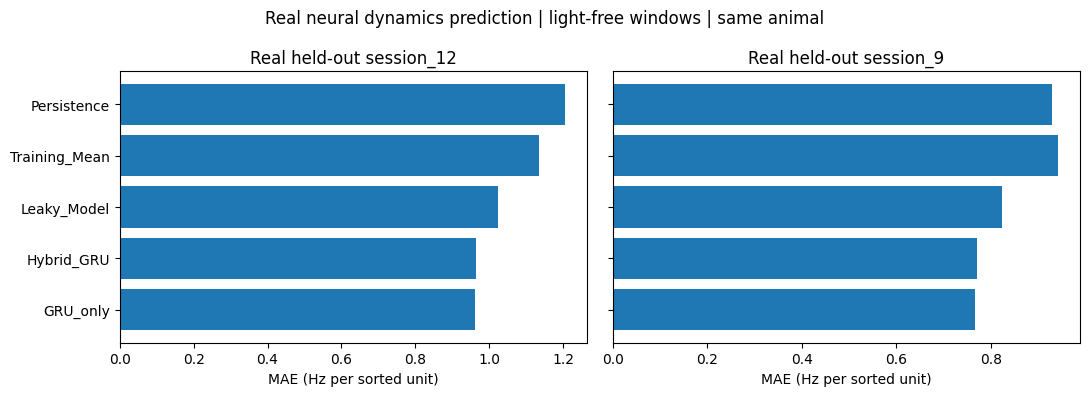

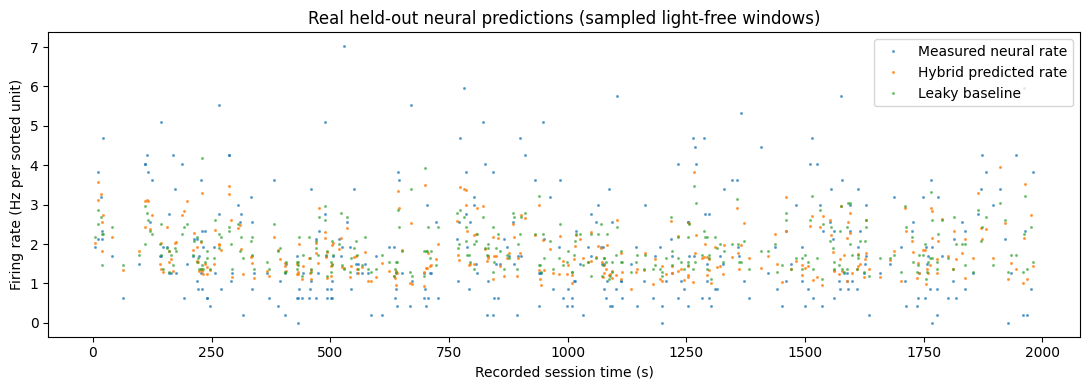

In [8]:
clean=metrics_df[metrics_df.group=='LIGHT_FREE']
fig,axs=plt.subplots(1,2,figsize=(11,4),sharey=True)
for ax,(fold,part) in zip(axs,clean.groupby('fold')):
    part=part.sort_values('MAE_Hz')
    ax.barh(part.model,part.MAE_Hz)
    ax.invert_yaxis();ax.set_xlabel('MAE (Hz per sorted unit)')
    ax.set_title(f'Real held-out {part.heldout_session.iloc[0]}')
fig.suptitle('Real neural dynamics prediction | light-free windows | same animal',fontsize=12)
fig.tight_layout();fig.savefig(OUT/'fig1_real_heldout_neural_MAE.png',dpi=180);plt.show()

pick=pred_df[pred_df.fold==1].sort_values('time_sec').iloc[:min(350,len(pred_df[pred_df.fold==1]))]
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(pick.time_sec,pick.actual_Hz,'.',markersize=2.5,alpha=.55,label='Measured neural rate')
ax.plot(pick.time_sec,pick.Hybrid_GRU_pred_Hz,'.',markersize=2.5,alpha=.65,label='Hybrid predicted rate')
ax.plot(pick.time_sec,pick.Leaky_Model_pred_Hz,'.',markersize=2.5,alpha=.5,label='Leaky baseline')
ax.set_xlabel('Recorded session time (s)');ax.set_ylabel('Firing rate (Hz per sorted unit)')
ax.set_title('Real held-out neural predictions (sampled light-free windows)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'fig2_real_neural_predicted_vs_observed.png',dpi=180);plt.show()

## 9 · REAL held-out multi-step free-running prediction (6 seconds)

**Why it matters:** One-step performance does not prove stable digital-twin rollouts. Here, the twin receives 2 seconds of **measured neural history**, then predicts 6 seconds of **neural activity without further observations**. We compare the predicted trajectory to **actually recorded** neural rates from entirely held-out sessions. Every test segment and its history must be free of light plus the temporal guard.

This is a deliberately difficult *free-running forecast*, not a reconstruction of stimulation-specific responses or a demonstration of optical control. The segments come from one mouse (two sessions).

REAL 6-second free-run averaged segment MAEs:
heldout_session  model      
session_12       Hybrid_GRU     1.139
                 Leaky_Model    1.173
                 Persistence    1.391
session_9        Hybrid_GRU     0.781
                 Leaky_Model    0.910
                 Persistence    1.319
Name: MAE_Hz, dtype: float64


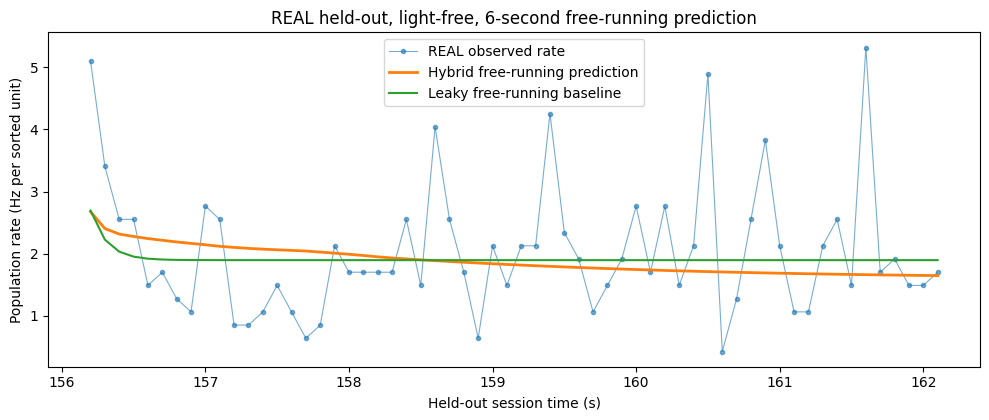

In [9]:
ROLLOUT_STEPS=60   # 6 seconds at 100-ms resolution
ROLLOUT_PER_SESSION=10

def simulate_unforced_real_twin(model,sc,params,history,steps=ROLLOUT_STEPS):
    hist=list(np.asarray(history,dtype=float))
    out=[]
    for i in range(steps):
        x=np.asarray(hist[-HISTORY_BINS:],dtype=np.float32)
        ex={'X':x[None,:],'y':np.zeros(1,dtype=np.float32),'last':np.asarray([x[-1]],dtype=np.float32)}
        next_rate=float(predict_model(model,ex,sc,params,'Hybrid_GRU')[0])
        hist.append(next_rate);out.append(next_rate)
    return np.asarray(out,dtype=np.float64)

def light_free_rollout_anchors(s,n_needed,seed):
    # Candidate windows are non-overlapping in time; biological independence is still NOT established.
    stride=HISTORY_BINS+ROLLOUT_STEPS+30
    anchor=np.arange(HISTORY_BINS+2,s['n_bins']-ROLLOUT_STEPS-2,stride)
    pref=np.r_[0,np.cumsum(s['near_light'].astype(np.int64))]
    valid=(pref[anchor+ROLLOUT_STEPS]-pref[anchor-HISTORY_BINS])==0
    anchor=anchor[valid]
    if len(anchor)<2:raise RuntimeError('No sufficiently long held-out light-free segments')
    rng=np.random.default_rng(seed)
    return np.sort(rng.choice(anchor,size=min(n_needed,len(anchor)),replace=False))

roll_rows=[]; roll_plot=None
for fold,modelinfo in SAVED.items():
    s=sessions[modelinfo['test_session']]
    anchors=light_free_rollout_anchors(s,ROLLOUT_PER_SESSION,SEED+fold)
    model=modelinfo['hybrid'];sc=modelinfo['scaler'];p=modelinfo['leaky']
    for k,a in enumerate(anchors):
        history=s['rate'][a-HISTORY_BINS:a]
        observed=s['rate'][a:a+ROLLOUT_STEPS].astype(np.float64)
        hybrid=simulate_unforced_real_twin(model,sc,p,history)
        leaky=[];last=float(history[-1])
        for _ in range(ROLLOUT_STEPS):
            last=float(leaky_predict(np.asarray([last]),p)[0]);leaky.append(last)
        forecasts={'Hybrid_GRU':hybrid,'Leaky_Model':np.asarray(leaky,dtype=float),
                   'Persistence':np.full(ROLLOUT_STEPS,history[-1])}
        for name,yp in forecasts.items():
            for period,stop in [('0_1s',10),('0_6s',ROLLOUT_STEPS)]:
                roll_rows.append({'fold':fold,'heldout_session':modelinfo['test_session'],
                                  'segment_id':k,'start_sec':float(a*BIN_SEC),
                                  'horizon':period,'model':name,**evaluate(observed[:stop],yp[:stop])})
        if roll_plot is None:roll_plot={'start_sec':a*BIN_SEC,'observed':observed,'hybrid':hybrid,
                                       'leaky':leaky,'session':modelinfo['test_session']}
roll_df=pd.DataFrame(roll_rows)
roll_df.to_csv(OUT/'real_heldout_6s_free_running_rollouts.csv',index=False)
print('REAL 6-second free-run averaged segment MAEs:')
print(roll_df[roll_df.horizon=='0_6s'].groupby(['heldout_session','model']).MAE_Hz.mean().round(3))
fig,ax=plt.subplots(figsize=(10,4.3))
x=roll_plot['start_sec']+np.arange(ROLLOUT_STEPS)*BIN_SEC
ax.plot(x,roll_plot['observed'],'.-',lw=.8,alpha=.6,label='REAL observed rate')
ax.plot(x,roll_plot['hybrid'],lw=2,label='Hybrid free-running prediction')
ax.plot(x,roll_plot['leaky'],lw=1.5,label='Leaky free-running baseline')
ax.set_xlabel('Held-out session time (s)');ax.set_ylabel('Population rate (Hz per sorted unit)')
ax.set_title('REAL held-out, light-free, 6-second free-running prediction')
ax.legend();fig.tight_layout();fig.savefig(OUT/'fig3_REAL_heldout_multistep_rollout.png',dpi=180);plt.show()


## 10 · Define the **hypothetical** optogenetic drive

The optical drive is **not fitted to the observed NWB response** because our Phase 2B/2C tests did not establish reliable light-specific effects. We use a dimensionless light action `u(t) ∈ [0,1]` and assume a first-order photocurrent proxy:

\[z_{t+1}=\rho z_t+(1-\rho)u_t,\qquad \rho=\exp(-\Delta t/\tau_{photo})\]

\[ r_{t+1}^{sim}=\max(0,\hat r_{t+1}^{hybrid} + \beta z_{t+1}) \]

- `τ_photo = 0.2 s` is an **illustrative assumption**, not an estimated opsin constant.
- `β` is an **assumed perturbation gain**, in Hz per unit normalized light drive. Positive and negative values represent hypothetical excitation and inhibition.
- The same initial observed state is replayed under different **counterfactual** light schedules. No optimization, efficacy, calibrated dose, or treatment safety claims are permitted.

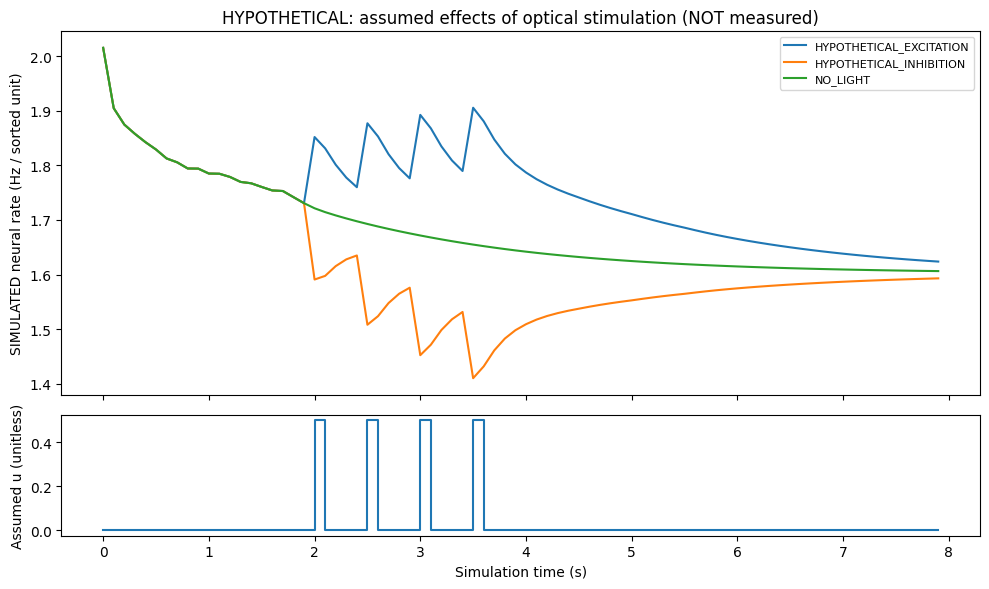

In [10]:
@torch.no_grad()
def one_step_hybrid(history_rates,model,sc,parameters):
    h=np.asarray(history_rates,dtype=np.float32)
    hist={'X':h[None,:],'y':np.zeros(1,dtype=np.float32),'last':np.array([h[-1]],dtype=np.float32)}
    return float(predict_model(model,hist,sc,parameters,'Hybrid_GRU')[0])

def scenario_simulation(model,sc,parameters,initial_history,action,assumed_beta_Hz,
                        tau_photo_sec=0.20):
    """Counterfactual simulator, NOT an estimate of optical response from recordings."""
    hist=list(map(float,initial_history))
    if len(hist)!=HISTORY_BINS:raise ValueError('Expected exact history length')
    rho=np.exp(-BIN_SEC/tau_photo_sec)
    z=0.0;rows=[]
    for step,u in enumerate(np.asarray(action,dtype=float)):
        if not 0<=u<=1:raise ValueError('Action must be unitless in [0,1]')
        z=rho*z+(1-rho)*float(u)
        off_prediction=one_step_hybrid(hist[-HISTORY_BINS:],model,sc,parameters)
        value=float(np.clip(off_prediction+assumed_beta_Hz*z,0,500))
        rows.append({'time_sec':step*BIN_SEC,'action_unitless':u,'filtered_action_unitless':z,
                     'unforced_prediction_Hz':off_prediction,
                     'simulated_rate_Hz':value,'assumed_beta_Hz':assumed_beta_Hz})
        hist.append(value)
    return pd.DataFrame(rows)

SIM_STEPS=80 # 8 seconds hypothetical exercise
light_schedule=np.zeros(SIM_STEPS,dtype=float)
# Four illustrative 100-ms light commands spaced by 500 ms; not claimed as original protocol.
light_schedule[[20,25,30,35]]=0.5
record=SAVED[1]
initial=record['test']['X'][0]
mu=record['leaky']['mu_Hz']
scenarios={'NO_LIGHT':0.0,'HYPOTHETICAL_EXCITATION':0.35*mu,
           'HYPOTHETICAL_INHIBITION':-0.35*mu}
SIM_ROWS=[]
for name,beta in scenarios.items():
    df=scenario_simulation(record['hybrid'],record['scaler'],record['leaky'],initial,
                           np.zeros(SIM_STEPS) if name=='NO_LIGHT' else light_schedule,beta)
    df['scenario']=name;SIM_ROWS.append(df)
SIM_DF=pd.concat(SIM_ROWS,ignore_index=True)
SIM_DF.to_csv(OUT/'SIMULATED_counterfactual_light_scenarios_NOT_OBSERVED.csv',index=False)

fig,axs=plt.subplots(2,1,figsize=(10,6),sharex=True,gridspec_kw={'height_ratios':[3,1]})
for name,df in SIM_DF.groupby('scenario'):
    axs[0].plot(df.time_sec,df.simulated_rate_Hz,label=name)
axs[0].set_ylabel('SIMULATED neural rate (Hz / sorted unit)')
axs[0].set_title('HYPOTHETICAL: assumed effects of optical stimulation (NOT measured)')
axs[0].legend(fontsize=8)
axs[1].step(np.arange(SIM_STEPS)*BIN_SEC,light_schedule,where='post')
axs[1].set_ylabel('Assumed u (unitless)');axs[1].set_xlabel('Simulation time (s)')
fig.tight_layout();fig.savefig(OUT/'fig4_SIMULATED_assumed_light_response.png',dpi=180);plt.show()

## 11 · Sensitivity and numerical plausibility checks (simulation only)

A serious simulation paper should show how conclusions change when **assumed optical efficacy** changes. We vary `β`, measure whether the model remains nonnegative/finite, and confirm the `β=0` run matches the no-light trajectory despite a nonzero stimulus schedule. These are *software and counterfactual behavior checks*, not physiological validation.

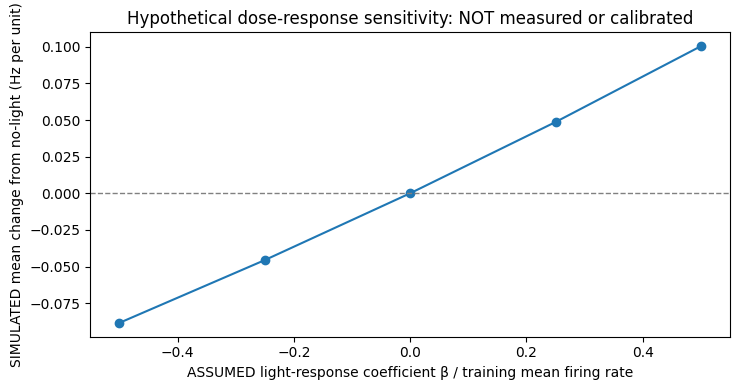

 assumed_beta_Hz  beta_relative_to_training_mu  mean_sim_rate_Hz  mean_change_from_no_light_Hz  minimum_sim_rate_Hz  maximum_sim_rate_Hz  finite  nonnegative
       -0.948321                         -0.50          1.591800                     -0.088464             1.306912             2.015506    True         True
       -0.474160                         -0.25          1.634651                     -0.045613             1.479314             2.015506    True         True
        0.000000                          0.00          1.680264                      0.000000             1.606304             2.015506    True         True
        0.474160                          0.25          1.728877                      0.048613             1.618282             2.015506    True         True
        0.948321                          0.50          1.780666                      0.100402             1.632806             2.015506    True         True


In [11]:
BETAS=np.array([-0.50,-0.25,0,0.25,0.50],dtype=float)*mu
SENS_ROWS=[];NO_ACT=np.zeros(SIM_STEPS)
reference=scenario_simulation(record['hybrid'],record['scaler'],record['leaky'],initial,NO_ACT,0)
for beta in BETAS:
    df=scenario_simulation(record['hybrid'],record['scaler'],record['leaky'],initial,light_schedule,float(beta))
    response=df.simulated_rate_Hz.to_numpy()
    base=reference.simulated_rate_Hz.to_numpy()
    SENS_ROWS.append({'assumed_beta_Hz':float(beta),'beta_relative_to_training_mu':float(beta/max(mu,1e-9)),
                      'mean_sim_rate_Hz':float(response.mean()),
                      'mean_change_from_no_light_Hz':float(np.mean(response-base)),
                      'minimum_sim_rate_Hz':float(response.min()),
                      'maximum_sim_rate_Hz':float(response.max()),
                      'finite':bool(np.all(np.isfinite(response))),
                      'nonnegative':bool(np.all(response>=0))})
sensitivity=pd.DataFrame(SENS_ROWS)
sensitivity.to_csv(OUT/'SIMULATED_parameter_sensitivity_NOT_VALIDATED.csv',index=False)
assert sensitivity.finite.all() and sensitivity.nonnegative.all()
assert abs(sensitivity.loc[np.isclose(sensitivity.assumed_beta_Hz,0),
                           'mean_change_from_no_light_Hz'].iloc[0])<1e-6
fig,ax=plt.subplots(figsize=(7.5,4))
ax.plot(sensitivity.beta_relative_to_training_mu,sensitivity.mean_change_from_no_light_Hz,'o-')
ax.axhline(0,ls='--',color='gray',lw=1)
ax.set_xlabel('ASSUMED light-response coefficient β / training mean firing rate')
ax.set_ylabel('SIMULATED mean change from no-light (Hz per unit)')
ax.set_title('Hypothetical dose-response sensitivity: NOT measured or calibrated')
fig.tight_layout();fig.savefig(OUT/'fig5_SIMULATED_beta_sensitivity.png',dpi=180);plt.show()
print(sensitivity.to_string(index=False))

## 12 · Report provenance, limitations, and export results

**Do not mix these evidence types in a paper:**

| Output group | What it means |
|---|---|
| `real_*.csv`, `fig1_real*`, `fig2_real*`, `fig3_REAL*` | Actual NWB spontaneous neural rate; measured cross-session prediction errors |
| `SIMULATED_*.csv`, `fig4_SIMULATED*`, `fig5_SIMULATED*` | Assumed light effects and software sensitivity checks; NOT observed intervention outcomes |
| Model checkpoints | Computational prototype only; do not deploy to medical devices |

**Next work after this notebook:** Confirm whether the hybrid GRU actually beats the leaky baseline on held-out real neural activity. Then Phase 3B can investigate richer biological constraints and calibration; Phase 4 uncertainty requires held-out calibration beyond this first same-animal study.

In [12]:
report={
  'project_phase':'3A - computational hybrid digital twin prototype',
  'created_utc':datetime.now(timezone.utc).isoformat(),
  'recordings':'DANDI 000568 / 0.230705.1633',
  'same_animal_across_sessions':True,
  'neural_prediction_target':'next 100-ms population firing rate (Hz per sorted neural unit)',
  'real_data_training':'training-session light-free windows only, with 0.3s guard',
  'train_test_splitting':'two held-out recording-session directions, same mouse, chronological internal validation',
  'model_architecture':'leaky nonnegative population rate + GRU residual hybrid',
  'real_neural_performance_file':'real_heldout_neural_dynamics_metrics.csv',
  'optical_perturbation_evidence':'hypothetical, not fitted and not validated against optogenetic response',
  'assumed_optical_time_constant_sec':0.20,
  'real_observed_light_data_used_for_training':'excluded from neural baseline training; used only for timing masks',
  'quick_mode':QUICK_MODE,'device':str(DEVICE),
  'limitations':[
     'DANDI 000568 provides both sessions from the same mouse: no independent-animal personalization.',
     'No human epileptiform activity or clinical seizure labels are part of this experiment.',
     'The mechanistic rate model is interpretable but is not an identified human neural circuit.',
     'Beta and photocurrent time constant are illustrative and not calibrated on the source dataset.',
     'Real-data prediction skill cannot substantiate simulated efficacy of optogenetic control.',
     'Closely spaced time windows remain correlated despite thinning; test windows are not independent biological samples.',
     'No uncertainty coverage or clinical safety metrics are established here.'
  ]
}
(OUT/'RESEARCH_SCOPE_AND_LIMITATIONS.json').write_text(json.dumps(report,indent=2))
(OUT/'README_RESULTS.txt').write_text(
    'REAL OBSERVATIONS: files starting real_ / fig1_real / fig2_real.\n'
    'HYPOTHETICAL SIMULATIONS: files starting SIMULATED_ / fig4_SIMULATED / fig5_SIMULATED.\n'
    'Same mouse in both sessions. Not epilepsy therapy. Optical perturbation beta is assumed.\n')
archive=ROOT/'phase3a_hybrid_digital_twin_results.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for path in sorted(OUT.iterdir()):
        if path.is_file():z.write(path,arcname=path.name)
print('RESULTS ZIP:',archive,'size MB:',round(archive.stat().st_size/1e6,2))
print('REAL data comparisons are in real_heldout_neural_dynamics_metrics.csv')
print('HYPOTHETICAL simulations are in SIMULATED_*.csv')

RESULTS ZIP: /kaggle/working/phase3a_hybrid_digital_twin_results.zip size MB: 0.62
REAL data comparisons are in real_heldout_neural_dynamics_metrics.csv
HYPOTHETICAL simulations are in SIMULATED_*.csv


## 13 · Interpretation and next milestone

1. **If Hybrid_GRU improves on both the Leaky_Model and the GRU_only baselines** on held-out sessions, the prototype supports the usefulness of a hybrid predictor **for spontaneous neural dynamics**.
2. **If not, retain the negative result.** We still have an executable prototype and can inspect validation loss, model bias, or stronger biological priors.
3. The optical plots show the *assumed mechanism's behavior*, not biological verification; changing `β` changes the results by construction.
4. Before a Q1 claim about closed-loop optogenetics, we would require real optogenetic intervention-response validation across independent biological samples.

**Next action:** After the Kaggle run completes, upload `phase3a_hybrid_digital_twin_results.zip`. We will inspect all model performance, calibration and stability checks and decide what to improve in Phase 3B.